In [1]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


Import the relevant modules

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, abspath, normpath
from stl import mesh
# for the triangle adjacency matrix.
from base.utils import find_neighbours_with_knn
# for laplacian based contraction
from base.LBC_centreline import return_LBC_centreline
# for the iterative path finder
from base import iterative_section_minimiser
# for the maximum spanning tree clearance method
from base.MST_centreline import return_MST_centrelines

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Define some custom plotting styles.

In [30]:
skeleton_kwargs = dict(color = "firebrick",
                       marker= "o",
                       s= 1, 
                       zorder = -10)
node_kwargs = dict(color = "k", 
           marker = "o", 
           s = 10, 
           zorder = 119,
            edgecolor = "white",
            linewidth = 0.7)

ct_kwargs = dict(color = "red",
                 lw = 1.2,
                 zorder = 118,
                 ls = "-")

mesh_kwargs = dict(color = "lightgrey",
                 zorder = -20, 
                 marker = "s",
                 s = 5)

start_kwargs = dict(color = "dodgerblue", 
           marker = "o", 
           s = 20, 
           zorder = 120,
            edgecolor = "black",
            linewidth = 1.1, 
            label = "source")
end_kwargs = dict(color = "fuchsia", 
           marker = "o", 
           s = 20, 
           zorder = 120,
            edgecolor = "black",
            linewidth = 1.1, 
            label = "target")

Importing the mesh data. We work on the mesh vertices and triangles for the contraction of the pointcloud as well as the computation of mesh-plane intersections.

In [86]:
## import the mesh data. 
mesh_fp =  "./temp/synthetic/straight_cylinder_L8_R1_stochastic.stl"
data = mesh.Mesh.from_file(mesh_fp)
conduit = split(mesh_fp)[-1][:-4]
datatype = "real"
if "synthetic" in mesh_fp:
    datatype = "synthetic"
print(conduit)


straight_cylinder_L8_R1_stochastic


We read the triangle adjacency matrix, and save it to a file for later retrieval, since this is a pre-computation step we only need to run once. 

In [87]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

We run the laplacian-based contraction algorithm.

In [88]:
lbc_centreline_fp = join("./temp/centrelines/", f"LBC_{conduit}_centreline.txt")

For demonstration purposes, we produce a figure containing the various stages of laplacian based contraction. 

In [89]:
from base.LBC_centreline import LBC
from base.utils import array_to_o3d

In [90]:
pcd = data.centroids
# convert to open3d object-
pcd = array_to_o3d(pcd)

In [91]:
DEMO_CONTRACTION = True

if DEMO_CONTRACTION == True:
    # initialise the list containing the stages of contraction. 
    skeleton_clouds = [] 
    for max_it_step in range(1,6):
        # set up the Laplacian-based contraction algorithm 
        lbc = LBC(point_cloud=pcd, 
                down_sample=0.2,
                init_attraction = 2, 
                init_contraction = 0.5, 
                max_iteration_steps=max_it_step)
        lbc.extract_skeleton()
        skeleton_clouds.append(lbc.contracted_point_cloud)


2026-01-19 16:33:54,279 - PCD #points: 1833
Volume ratio: 1.0. Contraction weights: 83.11003209145437. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  3.90it/s]2026-01-19 16:33:54,837 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 83.11003209145437. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  2.22it/s]
2026-01-19 16:33:54,909 - PCD #points: 1833


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 166.22006418290874. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  8.24it/s]2026-01-19 16:33:55,390 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 166.22006418290874. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  5.91it/s]
2026-01-19 16:33:55,427 - PCD #points: 1833


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 332.4401283658175. Attraction weights: 4.006983939035529. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  5.69it/s]2026-01-19 16:33:56,274 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 332.4401283658175. Attraction weights: 4.006983939035529. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  4.54it/s]
2026-01-19 16:33:56,339 - PCD #points: 1833


Contraction is Done.


Volume ratio: 0.33666520963567026. Contraction weights: 664.880256731635. Attraction weights: 56.81050385769377. Progress LBC: 100%|██████████| 4/4 [00:00<00:00,  5.97it/s]2026-01-19 16:33:57,317 - Contraction is Done.
Volume ratio: 0.33666520963567026. Contraction weights: 664.880256731635. Attraction weights: 56.81050385769377. Progress LBC: 100%|██████████| 4/4 [00:00<00:00,  4.67it/s]
2026-01-19 16:33:57,386 - PCD #points: 1833


Contraction is Done.


Volume ratio: 0.33666520963567026. Contraction weights: 664.880256731635. Attraction weights: 56.81050385769377. Progress LBC:  80%|████████  | 4/5 [00:00<00:00,  3.79it/s]2026-01-19 16:33:58,819 - Contraction is Done.
Volume ratio: 0.33666520963567026. Contraction weights: 664.880256731635. Attraction weights: 56.81050385769377. Progress LBC:  80%|████████  | 4/5 [00:01<00:00,  3.02it/s]

Contraction is Done.


Now we plot the various stages of decomposition. 

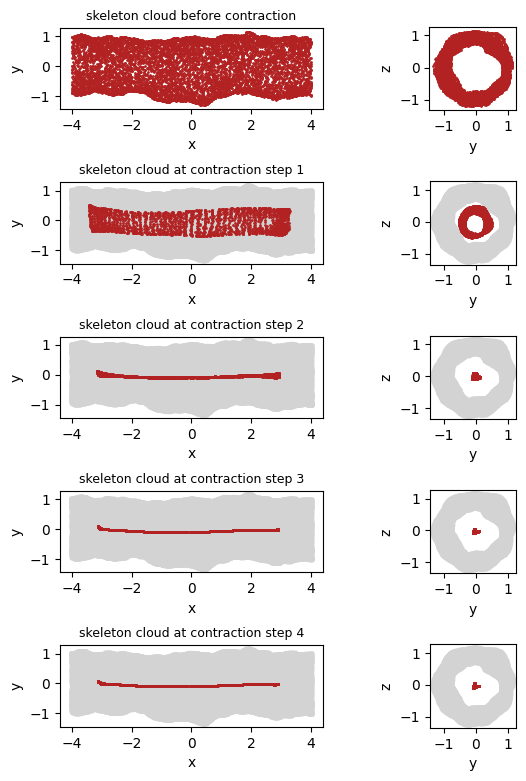

In [92]:
if DEMO_CONTRACTION == True:
    fig, axes = plt.subplots(5, 2, figsize= (6.5, 8)) 

    # plot the first point cloud, before contraction. 
    axes[0, 0].scatter(*data.centroids[::75, [0, 1]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

    axes[0, 0].set_aspect("equal")
    axes[0, 0].set_xlabel("x")
    axes[0, 0].set_ylabel("y")

    axes[0, 1].scatter(*data.centroids[::75, [1, 2]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

    axes[0, 1].set_aspect("equal")
    axes[0, 1].set_xlabel("y")
    axes[0, 1].set_ylabel("z")

    k = 0
    for cloud, ax in zip(skeleton_clouds, axes[1:, 0]):
        k+=1
        the_pcd = np.asarray(cloud.points)
        ax.scatter(*the_pcd[:, [0, 1]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax.scatter(*data.centroids[::20, [0, 1]].T, **mesh_kwargs)
        
        ax.set_title(f"skeleton cloud at contraction step {k}", fontdict=dict(fontsize=9))
        ax.set_aspect("equal")
        ax.set_xlabel("x")
        ax.set_ylabel("y")

    k = 0
    for cloud, ax in zip(skeleton_clouds, axes[1:, 1]):
        k+=1
        the_pcd = np.asarray(cloud.points)
        ax.scatter(*the_pcd[:, [1, 2]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax.scatter(*data.centroids[::20, [1, 2]].T, **mesh_kwargs)
        
        ax.set_aspect("equal")
        ax.set_xlabel("y")
        ax.set_ylabel("z")

    axes[0, 0].set_title("skeleton cloud before contraction", fontdict=dict(fontsize=9))
    plt.tight_layout(pad = 2)
    plt.savefig(f"./temp/figures/{conduit}_lbc_contraction_steps.png", dpi = 300)
    plt.show()

In [93]:
# definition of processing metaparameters
lbc_args = dict(init_attraction = 2, init_contraction = 0.5, down_sample = 0.2)
ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = 0.4)

In [94]:
out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)


read file in 0.0000s


2026-01-19 16:34:07,553 - PCD #points: 1833


contracted file in 2.0961s


Volume ratio: 0.33692202958476364. Contraction weights: 664.8169826736014. Attraction weights: 56.783449190579034. Progress LBC:  20%|██        | 4/20 [00:01<00:08,  1.94it/s]2026-01-19 16:34:10,247 - Contraction is Done.
Volume ratio: 0.33692202958476364. Contraction weights: 664.8169826736014. Attraction weights: 56.783449190579034. Progress LBC:  20%|██        | 4/20 [00:02<00:09,  1.61it/s]

Contraction is Done.
extracted skeleton in 2.7325s
downsampled the centreline cloud in 0.0000s
16
found largest component in 0.0015s
computed minimum spanning tree in 0.0195s
created graph instance of the centreline in  0.0010s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 2 leaves. Need to identify the best path.


In [95]:
# we now save the cloud contracted centreline.
LBC_ct = out_LBC["sparse_cloud"][np.array(out_LBC["centreline"]).astype(int)]

np.savetxt(lbc_centreline_fp, LBC_ct, fmt= "%.3e")

In [96]:
# these are the source and target points. 
P1 = LBC_ct[0]
P2 = LBC_ct[-1]

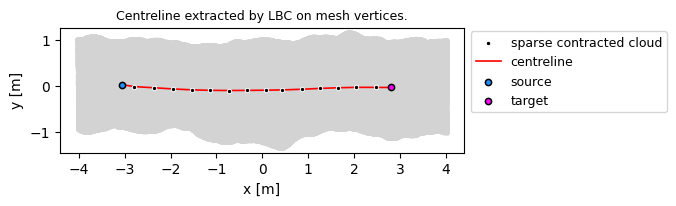

In [97]:
fig, ax = plt.subplots(figsize = (7, 5))

# plot the sparse cloud
ax.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, 
           **node_kwargs, label = "sparse contracted cloud")

# plot the LBC estimate of the centreline 
ax.plot(*LBC_ct[:, [0, 1]].T,
        **ct_kwargs, label = "centreline")

# plot the start and end point
ax.scatter(*P1[[0, 1]],
           **start_kwargs)
ax.scatter(*P2[[0, 1]],
           **end_kwargs)

# plot the mesh 
ax.scatter(*data.centroids[::5, [0, 1]].T, 
           **mesh_kwargs)

# beautify the graph 
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize = 9, bbox_to_anchor=(1, 1.02), loc = "upper left")
ax.set_title("Centreline extracted by LBC on mesh vertices.", fontdict=dict(fontsize=9))

plt.tight_layout()
plt.savefig(f"./temp/figures/{conduit}_extremities_lbc_contract.png", dpi = 300)

Calling the voxelizer from Otfried. 

In [98]:
voxset_fp = mesh_fp[:-4] + "_voxset.vxl"
print(voxset_fp, mesh_fp)
voxelsize = 0.2
out_MST = return_MST_centrelines(mesh_fp, voxset_path=voxset_fp, 
                             delta = int(voxelsize*1000), 
                             P1=P1, 
                             P2=P2, 
                             verbose = False, 
                             datatype=datatype)

./temp/synthetic/straight_cylinder_L8_R1_stochastic_voxset.vxl ./temp/synthetic/straight_cylinder_L8_R1_stochastic.stl


Read 'c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines\temp\synthetic\straight_cylinder_L8_R1_stochastic_voxset.vxl': 265,315 vertices and 2,998 grid points,
Added edges in 5.4 sec.
Computed maximum spanning tree for clearance in 0.2 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.


Polyline has 30 vertices
Simplified polyline has 2 vertices


simplified polyline has fewer than 2 vertices. Impossible to simplify further.


Now we plot the demo figure showing not only the mesh, but its voxelised version, the centreline identified and the simplifications.

In [99]:
from matplotlib.colors import Normalize 
from matplotlib.cm import viridis, ScalarMappable
from matplotlib.gridspec import GridSpec

In [100]:
jagged_edges = np.loadtxt(f"temp//{datatype}//{conduit}_unzigzag_edges.xyz")
jagged_centreline = np.loadtxt(f"temp//centrelines//MST_{conduit}_{int(voxelsize*1000)}_jagged_centreline.txt")

In [101]:
mst_edges = np.loadtxt(f"temp//{datatype}//{conduit}_MST_edges.xyz")

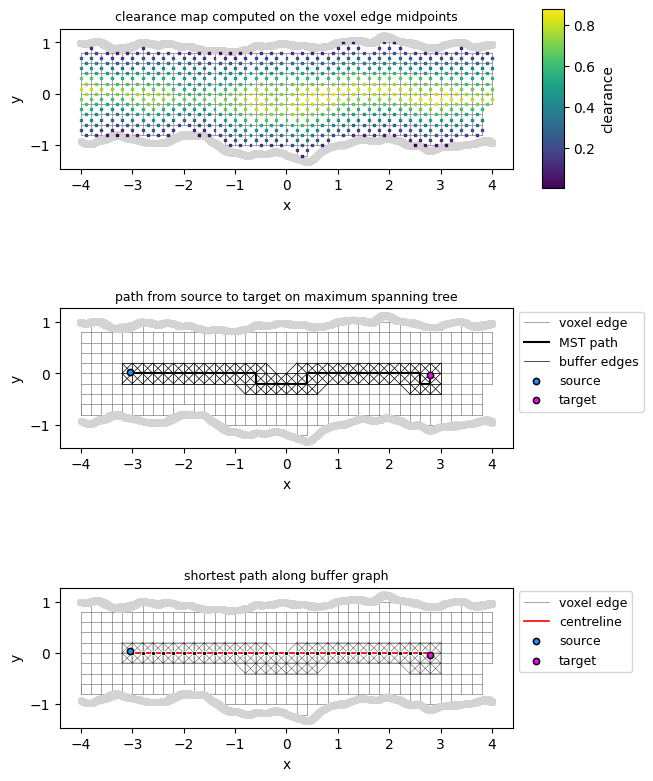

In [102]:
DEMO_MST = True

if DEMO_MST == True:
    
    edges = np.loadtxt(f"temp//{datatype}//{conduit}_edges.xyz")
    edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

    jagged_edges = np.loadtxt(f"temp//{datatype}//{conduit}_unzigzag_edges.xyz")
    jagged_edges_mask = np.logical_and(jagged_edges[:, 2] == 0,jagged_edges[:, 5] == 0) 

    mst_edges = np.loadtxt(f"temp//{datatype}//{conduit}_mst_edges.xyz")
    mst_edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

    vmin = np.min(edges[:, 6]/1000)
    vmax = np.max(edges[:, 6]/1000)

    norm = Normalize(vmin, vmax)
    mappable = ScalarMappable(norm)

    edges_midpoints = np.loadtxt(f"temp//{datatype}//{conduit}_edges_midpoints.xyz")

    gs = GridSpec(20, 20)
    fig = plt.figure(figsize = (6.5, 12))
    
    ax = fig.add_subplot(gs[0:4, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)
    

    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    ax.set_title("clearance map computed on the voxel edge midpoints", fontdict= dict(fontsize=9))
    mask = np.abs(edges_midpoints[:, 2]) < 0.05
    ax.scatter(*edges_midpoints[mask][:, [0, 1]].T, c=edges_midpoints[mask, 3], zorder = -10, marker="s", s= 2)
    
    cax = fig.add_subplot(gs[0:4, 19:])
    cb = plt.colorbar(mappable, cax =cax, fraction=0.01)
    cb.set_label("clearance")
    ax.set_aspect("equal")


    ax.set_xlabel("x")
    ax.set_ylabel("y")


    ax = fig.add_subplot(gs[6:10, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)
    ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")
    
    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    
    
    ax.set_title("path from source to target on maximum spanning tree", fontdict= dict(fontsize=9))
    
    # plot the jagged centreline
    ax.plot(*jagged_centreline[:, [0, 1]].T, zorder = 100, color = "k", label = "MST path")
    ax.plot(*jagged_centreline[:, [0, 1]].T, zorder = 95, color = "white", lw = 1.5)
    
    for jagged_edge, jagged_edge_mask in zip(jagged_edges, jagged_edges_mask):
        if jagged_edge_mask:
            ax.plot(jagged_edge[[0,3]],jagged_edge[[1,4]], color = "k", zorder = -10, lw = 0.5)
    
    ax.plot(jagged_edges[0, [0,3]],jagged_edges[0, [1,4]], color = "k", zorder = -10, lw = 0.5, label ="buffer edges")
    

    # plot the source and target
    ax.scatter(*P1[[0, 1]],**start_kwargs)
    ax.scatter(*P2[[0, 1]], **end_kwargs)

    # define the colorbar for the mesh midpoints. 
    ax.legend(loc = "upper left", bbox_to_anchor= (1,1.02), fontsize = 9)
    ax.set_aspect("equal")

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax = fig.add_subplot(gs[12:16, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -20, lw = 0.5)
    ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")

    
    # plot the centreline
    ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs, label = "centreline")
    # plot the centreline nodes
    ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
           **node_kwargs)
    for jagged_edge, jagged_edge_mask in zip(jagged_edges, jagged_edges_mask):
        if jagged_edge_mask:
            ax.plot(jagged_edge[[0,3]],jagged_edge[[1,4]], color = "k", zorder = -10, lw = 0.25)
    
    
    ax.set_title("shortest path along buffer graph", fontdict= dict(fontsize=9))

    # plot the source and target
    ax.scatter(*P1[[0, 1]],**start_kwargs)
    ax.scatter(*P2[[0, 1]], **end_kwargs)


    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    
    ax.legend(loc="upper left", fontsize = 9, bbox_to_anchor=(1., 1.02))
    ax.set_aspect("equal")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.savefig(f"./temp/figures/{conduit}_edge_clearance_map.png", dpi = 300)
    plt.savefig(f"./temp/figures/{conduit}_edge_clearance_map.pdf")

    plt.show()

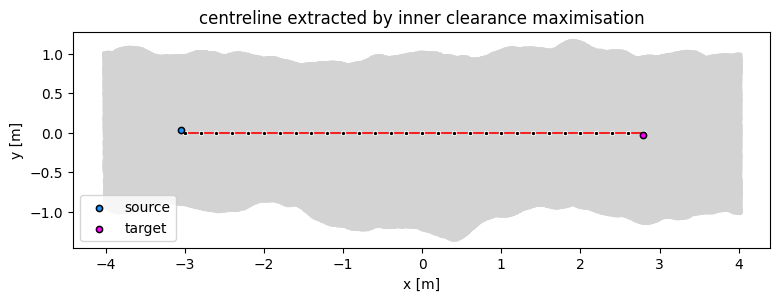

In [103]:
fig, ax = plt.subplots(figsize = (9, 5))

# plot the source and target
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

# plot the centreline
ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs)
# plot the centreline nodes
ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
           **node_kwargs)

## the below can coincide with the raw centrespline if we're not careful. 
#ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T, "-o", markersize =2, color = "k")
#plt.plot(*np.array(out_MST["centerspline_fit1"])[:, [0, 1]].T, "-o", markersize =2, color = "b")

ax.set_title("centreline extracted by inner clearance maximisation")
ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

plt.savefig(f"./temp/figures/{conduit}_extremities_MST_best_path.png", dpi = 300)


For the initial state of the iterative section minimiser, we have to find an initial normal vector. We use the neighbouring LBC centreline point and subtract to get a normal vector in an approximately optimal position.

In [104]:
nP0 = np.diff(LBC_ct[:2], axis =0)
nP0 /= np.linalg.norm(nP0)
np0 = nP0.flatten()

In the iterative section minimiser, we define the curvilinear distance of the LBC centreline as our expected centreline total curvilinear distance. We grow this expected distance by 5% to allow for extra tortuosity. This gives a natural upper bound of the number of iteration steps in our minimiser. 

In [105]:
L = np.sum(np.linalg.norm(np.diff(LBC_ct, axis =0), axis = 1))

In [106]:
out_iterative = iterative_section_minimiser.iterative_pathfinder(mesh_data=data,
                                                 P_start=P1,
                                                 nP0=nP0.flatten(),
                                                 P_end=P2, L=L, ds = 0.4, eps= 0.0001)

 94%|█████████▍| 17/18.0 [05:59<00:21, 21.13s/it]


We can finally extract the centreline from this process.

In [107]:
iterative_ct = out_iterative["centreline"]

In [108]:
iterative_ct_fp = join("./temp/centrelines/", f"iterative_{conduit}_centreline.txt") 

np.savetxt(iterative_ct_fp, iterative_ct)

c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


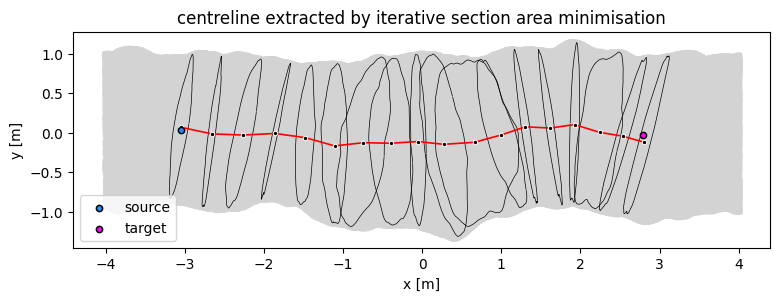

In [109]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs)

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs)

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)


ax.set_title("centreline extracted by iterative section area minimisation")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal")
ax.legend()

plt.savefig(f"./temp/figures/{conduit}_extremities_iterative_pathfinder.png", dpi = 300)
plt.savefig(f"./temp/figures/{conduit}_extremities_iterative_pathfinder.pdf")



Now we can make a comparison of all three methods for a paper figure. 

In [ ]:
fig, axes = plt.subplots(3, 1, figsize = (9, 11))
## laplacian based contraction 
ax  = axes[0]
# plot the sparse cloud
ax.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, 
           **node_kwargs, label = "sparse contracted cloud")

# plot the LBC estimate of the centreline 
ax.plot(*LBC_ct[:, [0, 1]].T,
        **ct_kwargs, label = "centreline")

# plot the start and end point
ax.scatter(*P1[[0, 1]],
           **start_kwargs)
ax.scatter(*P2[[0, 1]],
           **end_kwargs)

# plot the mesh 
ax.scatter(*data.centroids[::5, [0, 1]].T, 
           **mesh_kwargs)

# beautify the graph 
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize = 10)

## maximum spanning tree. 
ax = axes[1]
# plot the source and target
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

# plot the centreline
ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs)
# plot the centreline nodes
ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
           **node_kwargs, label = "voxel edge mid point")

## the below can coincide with the raw centrespline if we're not careful. 
#ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T, "-o", markersize =2, color = "k")
#plt.plot(*np.array(out_MST["centerspline_fit-simplified"])[:, [0, 1]].T, "-o", markersize =2, color = "r")
#plt.plot(*np.array(out_MST["centerspline_fit1"])[:, [0, 1]].T, "-o", markersize =2, color = "b")

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize=10)

## iterative. 
ax = axes[2]
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs, label = "section centre of mass")

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs)

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f"./temp/figures/{conduit}_centreline_comparisons.png", dpi = 300)

## Comparing the various centrelines

we use the Fréchet distance to measure how accurate each centreline is to the geometric centreline expected for synthetic conduits. 

In [ ]:
from base.frechet_dist import frdist
from base.refine_centreline import refine 

In [ ]:
MST_ct = np.array(out_MST["raw"])

In [ ]:
for steps in (0, 2, 5, 10, 20):
    print(f"steps: {steps}\n===========")
    print(frdist(refine(LBC_ct, steps), refine(MST_ct, steps)))
    print(frdist(refine(LBC_ct, steps), refine(iterative_ct, steps)))

In [ ]:
print(frdist(LBC_ct, MST_ct))
print(frdist(LBC_ct, iterative_ct))
print(frdist(MST_ct, iterative_ct))
